# Dynamic Mode Decomposition (DMD)
## Learning the modes of a time series, and using them to predict

###Prof. Victor S. Batista
**CHEM 584: Introduction to Machine Learning and Quantum Computing**

You have watched a system evolve and recorded a **movie**: a sequence of snapshots $v_1, v_2,\dots,v_n$ taken every $\tau$ units of time. Each snapshot is a list of $N$ numbers: the concentrations of $N$ species, a spectrum measured at $N$ wavelengths, the pixels of an image. **DMD** finds, from the movie alone,

1. a few characteristic **modes**: patterns $\Gamma_k$ (vectors of $N$ numbers), each with its own **decay or growth rate** and **oscillation frequency**; and
2. a **prediction** of what happens at later times, made by letting each mode evolve on its own.

No kinetic model is assumed. Everything is done with linear algebra.

### What you will do

| Part | Content |
|---|---|
| **A** | A linear-algebra refresher, with code: eigenvectors, modes that evolve independently, the SVD |
| **B** | DMD derived and implemented step by step, on a tiny reaction you can check by hand |
| **C** | A realistic chemical example (time-resolved spectra of A → B → C): DMD recovers the rate constants and predicts the future |
| **D** | An exercise: a two-dimensional Gaussian whose centre oscillates. DMD analyses the movie well, but **fails to predict**, which teaches us when DMD works |
| **E** | Summary, exercises, references |

### How to run this notebook
Run the cells from top to bottom (**Runtime → Run all**, or step through them one at a time, which is better the first time). Everything runs on a normal CPU runtime in a few seconds per cell; no GPU and no extra installation are needed. Cells marked **Your turn** contain a value to change: change it and re-run to see what happens.

**Prerequisites:** basic Python and NumPy. The linear algebra is reviewed in Part A, so a rusty memory of eigenvalues and the SVD is fine.

## 0. Setup

In [1]:
import numpy as np
import scipy.linalg as lin
import matplotlib.pyplot as plt
from matplotlib import animation

np.set_printoptions(precision=4, suppress=True, linewidth=120)   # tidy printing of arrays
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(0)                                   # fixed random numbers: reproducible results
print("numpy", np.__version__)

numpy 2.4.6


---
# Part A. A linear-algebra refresher

### A.1 Snapshots, matrices and shapes

A **snapshot** $v_j$ is a column vector with $N$ entries. We store many snapshots side by side as the **columns** of a matrix. A matrix with $N$ rows and $m$ columns is an $N\times m$ matrix, and a product of an $N\times m$ matrix with an $m\times p$ matrix is $N\times p$. Checking shapes is the best way to catch mistakes, and in NumPy it is one attribute: `array.shape`.

**Running example.** A first-order reaction A → B. The snapshot is $v=([\mathrm A],[\mathrm B])^T$ (so $N=2$). We choose the time step $\tau$ such that in each step **half** of the remaining A turns into B. Starting from pure A, $v_1=(1,0)^T$.

### A.2 A matrix is a machine that advances the system by one time step

If the dynamics is **linear**, one step transforms each snapshot into the next by a fixed $N\times N$ matrix $A$ (the *propagator*):
$$v_{j+1}=A\,v_j,\qquad\text{so}\qquad v_j=A^{\,j-1}v_1 .$$
For our reaction, half of A converts to B: $[\mathrm A]_{j+1}=\tfrac12[\mathrm A]_j$ and $[\mathrm B]_{j+1}=\tfrac12[\mathrm A]_j+[\mathrm B]_j$, i.e.
$$A=\begin{pmatrix}1/2&0\\1/2&1\end{pmatrix}.$$

V (columns = snapshots v_1 ... v_6), shape (2, 6)
[[1.     0.5    0.25   0.125  0.0625 0.0312]
 [0.     0.5    0.75   0.875  0.9375 0.9688]]


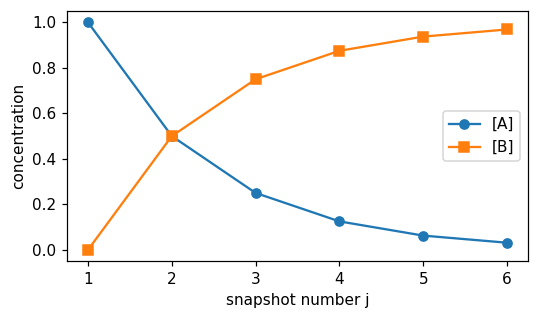

In [2]:
A_true = np.array([[0.5, 0.0],
                   [0.5, 1.0]])            # the propagator of A -> B (half of A converts per step)
v1 = np.array([1.0, 0.0])                  # initial snapshot: pure A

# Generate the "movie": v_{j+1} = A v_j
n = 6
V = np.zeros((2, n))
V[:, 0] = v1
for j in range(1, n):
    V[:, j] = A_true @ V[:, j - 1]

print("V (columns = snapshots v_1 ... v_6), shape", V.shape)
print(V)

plt.figure(figsize=(5, 3))
plt.plot(range(1, n + 1), V[0], "o-", label="[A]")
plt.plot(range(1, n + 1), V[1], "s-", label="[B]")
plt.xlabel("snapshot number j"); plt.ylabel("concentration"); plt.legend(); plt.tight_layout(); plt.show()

### A.3 Eigenvalues and eigenvectors: directions that are only stretched

Most vectors are both stretched and rotated by $A$. Some special vectors $\Gamma_k$ are **not rotated**; they are only multiplied by a number $\lambda_k$ (possibly complex):
$$A\Gamma_k=\lambda_k\Gamma_k .$$
They are the **eigenvectors**, and $\lambda_k$ the **eigenvalues**. An eigenvector is only defined up to a constant factor (if $\Gamma_k$ is one, so is $5\Gamma_k$). NumPy computes them with `np.linalg.eig`.

In [3]:
lam, Gamma = np.linalg.eig(A_true)         # columns of Gamma are the eigenvectors
print("eigenvalues:", lam)
print("eigenvectors (columns, normalised to length 1):")
print(Gamma)

# check A Gamma_k = lambda_k Gamma_k   (the difference must be ~0)
print("max |A Gamma - Gamma lambda| =", np.abs(A_true @ Gamma - Gamma * lam).max())

eigenvalues: [1.  0.5]
eigenvectors (columns, normalised to length 1):
[[ 0.      0.7071]
 [ 1.     -0.7071]]
max |A Gamma - Gamma lambda| = 0.0


The eigenvalue $\lambda=1$ belongs to $\Gamma\propto(0,1)^T$ (pure B: nothing happens to it any more, the **final state**), and $\lambda=\tfrac12$ belongs to $\Gamma\propto(1,-1)^T$ (A converting into B, which shrinks by half every step).

### A.4 Why eigenvectors help: the modes evolve independently

Suppose the initial state is a sum of eigenvectors, $v_1=\sum_k c_k\Gamma_k$. Each application of $A$ multiplies each term by its own $\lambda_k$, so
$$v_j=A^{\,j-1}v_1=\sum_k c_k\,\lambda_k^{\,j-1}\,\Gamma_k .$$
A coupled problem became a set of independent one-number problems. This is the key formula of the whole tutorial.

**How do we find the coefficients $c_k$?** If the eigenvectors were orthonormal we could use $c_k=\Gamma_k^\dagger v_1$ ("project onto each axis"). For a general, non-symmetric $A$ they are **not orthogonal**, and this shortcut is wrong. The correct recipe is the least-squares solution of $\Gamma c\approx v_1$:
$$c=S^{-1}\,\Gamma^\dagger v_1,\qquad S=\Gamma^\dagger\Gamma\ \ (\text{the overlap matrix},\ S_{jk}=\Gamma_j^\dagger\Gamma_k).$$
($\dagger$ means conjugate transpose; for real vectors it is the ordinary transpose.) Let's see the difference.

In [4]:
c_naive = Gamma.conj().T @ v1                                   # WRONG here: eigenvectors are not orthogonal
S = Gamma.conj().T @ Gamma                                      # overlap matrix
c = np.linalg.solve(S, Gamma.conj().T @ v1)                     # correct coefficients

print("overlap matrix S (not the identity!):\n", S)
print("naive coefficients  :", c_naive, " -> reconstructed v_1 =", Gamma @ c_naive)
print("overlap coefficients:", c,       " -> reconstructed v_1 =", Gamma @ c)

# Now use  v_j = sum_k c_k lambda_k^(j-1) Gamma_k  to rebuild the whole movie
j = np.arange(n)                                                # j-1 = 0,1,...,5
V_modes = (Gamma @ (c[:, None] * lam[:, None] ** j[None, :])).real
print("\nmovie rebuilt from the modes equals the original movie:", np.allclose(V_modes, V))

overlap matrix S (not the identity!):
 [[ 1.     -0.7071]
 [-0.7071  1.    ]]
naive coefficients  : [0.     0.7071]  -> reconstructed v_1 = [ 0.5 -0.5]
overlap coefficients: [1.     1.4142]  -> reconstructed v_1 = [1. 0.]

movie rebuilt from the modes equals the original movie: True


### A.5 Continuous time: decay rates and frequencies

If the system evolves continuously, $\dot v=\mathcal A\,v$, then one time step is $A=e^{\mathcal A\tau}$. If $\Gamma_k$ is an eigenvector of $\mathcal A$ with eigenvalue $\mu_k$, then $A\Gamma_k=e^{\mu_k\tau}\Gamma_k$: **the same eigenvectors, but different eigenvalues**,
$$\lambda_k=e^{\mu_k\tau},\qquad \mu_k=\frac{\ln\lambda_k}{\tau}.$$
Writing $\lambda_k=|\lambda_k|e^{i\theta_k}$: $\mu_k=\ln|\lambda_k|/\tau+i\,\theta_k/\tau$. The **real part** is the growth ($>0$) or decay ($<0$) rate and the **imaginary part** is the angular frequency of the oscillation:

| eigenvalue | meaning |
|---|---|
| $\lvert\lambda\rvert<1$ | decays, at rate $\ln\lvert\lambda\rvert/\tau$ |
| $\lvert\lambda\rvert=1$ | persists: conserved quantity, final state, or pure oscillation |
| $\lvert\lambda\rvert>1$ | grows exponentially (a warning sign when you extrapolate) |
| $\operatorname{Im}\lambda\ne0$ | oscillates with angular frequency $\arg(\lambda)/\tau$ (conjugate pairs for real data) |

In [5]:
tau = 1.0
mu = np.log(lam.astype(complex)) / tau          # mu_k = ln(lambda_k)/tau
print("lambda =", lam)
print("mu     =", mu.real, "  (units 1/time)")
print("k = ln 2 =", np.log(2), "-> the decaying mode has mu = -k:", np.isclose(mu.real.min(), -np.log(2)))

lambda = [1.  0.5]
mu     = [ 0.     -0.6931]   (units 1/time)
k = ln 2 = 0.6931471805599453 -> the decaying mode has mu = -k: True


### A.6 The singular value decomposition (SVD)

Any $N\times m$ matrix $X$ can be written
$$X=U\,\Sigma\,V^T=\sum_k\sigma_k\,u_kv_k^T .$$
* the columns $u_k$ of $U$ (length $N$) are orthonormal **patterns** (in species / wavelength space),
* the columns $v_k$ of $V$ (length $m$) are orthonormal **time profiles**,
* $\Sigma$ is diagonal with the **singular values** $\sigma_1\ge\sigma_2\ge\dots\ge0$: the importance of each layer.

So the data are a sum of "layers": one pattern × one time profile × its importance. Layers with tiny $\sigma_k$ are mostly noise, so we keep only the $r$ layers with $\sigma_k>\epsilon\,\sigma_1$ (**truncation**, a form of regularisation).

The **pseudo-inverse** $X^+=V\Sigma^{-1}U^T$ is the best substitute for the inverse of a non-square matrix: it gives the least-squares solution of linear equations. It is the tool that lets us compute a propagator from data.

In [6]:
X = V[:, :-1]                      # snapshots v_1 ... v_5   (2 x 5)
Y = V[:, 1:]                       # snapshots v_2 ... v_6   (2 x 5): the same movie, shifted by one step

U, s, Vh = np.linalg.svd(X, full_matrices=False)       # X = U diag(s) Vh      (Vh is V^T)
print("shapes  U:", U.shape, " s:", s.shape, " Vh:", Vh.shape)
print("singular values:", s)

layers = [s[k] * np.outer(U[:, k], Vh[k]) for k in range(len(s))]
print("sum of the layers reproduces X:", np.allclose(sum(layers), X))

X_pinv = Vh.T @ np.diag(1.0 / s) @ U.T                 # pseudo-inverse  X^+ = V S^-1 U^T
print("same as NumPy's pinv:", np.allclose(X_pinv, np.linalg.pinv(X)))

# The punchline: the propagator that maps X to Y is  A = Y X^+  -- computed from DATA only
A_est = Y @ X_pinv
print("\nA estimated from the movie, A = Y X^+ :\n", A_est)
print("true A:\n", A_true)

shapes  U: (2, 2)  s: (2,)  Vh: (2, 5)
singular values: [1.6495 1.0335]
sum of the layers reproduces X: True
same as NumPy's pinv: True

A estimated from the movie, A = Y X^+ :
 [[0.5 0. ]
 [0.5 1. ]]
true A:
 [[0.5 0. ]
 [0.5 1. ]]


We recovered the true propagator from the snapshots alone. In general $N\gg n$, so $A=YX^+$ is a huge $N\times N$ matrix that we would not want to build; Part B shows how to avoid it.

### Check yourself
1. In the cell above, `X` is $2\times5$. What are the shapes of `U`, `s`, `Vh`?
2. Why does `c_naive` fail while the overlap formula works?

<details><summary>Answers</summary>

1. `U`: $2\times2$, `s`: 2 numbers, `Vh`: $2\times5$ (reduced SVD, `full_matrices=False`).
2. The naive formula assumes orthonormal eigenvectors; here $S\neq I$, so the eigenvectors are not orthogonal and the overlap matrix must be included.
</details>

---
# Part B. DMD step by step

### The setting
We have the snapshot matrix $V=[v_1\ v_2\cdots v_n]$ ($N\times n$) and form two shifted copies, both $N\times(n-1)$:
$$X=[v_1\cdots v_{n-1}],\qquad Y=[v_2\cdots v_n],\qquad\text{so that}\qquad Y\approx AX .$$
The relation is only *approximate* in real data (noise, nonlinearity), and the $N\times N$ matrix $A$ has far more entries than the data can fix. DMD takes $A=YX^+$ (least squares, smallest norm); with the truncated SVD $X\approx U\Sigma V^T$:
$$A=Y\,V\Sigma^{-1}U^T .$$
This is a huge matrix and we never build it. All we need is a small $r\times r$ one.

### The six steps

**Step 1 – SVD of $X$**, keeping $r$ singular values.

**Step 2 – the small matrix.** Multiply $Y=AU\Sigma V^T$ on the right by $V\Sigma^{-1}$: $YV\Sigma^{-1}=AU$. Multiply on the left by $U^T$:
$$\tilde A=U^TAU=U^T\,Y\,V\Sigma^{-1}\qquad(r\times r).$$
It is the propagator written in the coordinates of the $r$ dominant patterns.

**Step 3 – the small eigenproblem** $\tilde A\tilde\Gamma_k=\lambda_k\tilde\Gamma_k$. These $\lambda_k$ are eigenvalues of $A$: if $A\Gamma=\lambda\Gamma$ with $\Gamma=U\tilde\Gamma$, multiplying by $U^T$ gives exactly this equation.

**Step 4 – the modes** in the original $N$-dimensional space (the *exact DMD modes*):
$$\Gamma_k=\lambda_k^{-1}\,Y\,V\Sigma^{-1}\,\tilde\Gamma_k .$$
(These are true eigenvectors of $A=YV\Sigma^{-1}U^T$: $A\Gamma_k=\lambda_k^{-1}YV\Sigma^{-1}\tilde A\tilde\Gamma_k=YV\Sigma^{-1}\tilde\Gamma_k=\lambda_k\Gamma_k$. In words: the mode is "the projected mode $U\tilde\Gamma_k$ advanced by one step, divided by $\lambda_k$".)

**Step 5 – amplitudes** from the initial state with the overlap matrix: $c=(\Gamma^\dagger\Gamma)^{-1}\Gamma^\dagger v_1$.

**Step 6 – prediction:** $v_j=\sum_kc_k\lambda_k^{\,j-1}\Gamma_k$. Using $j>n$ **extrapolates** the data to the future.

Let's do it on the A → B movie, where we know the answer: $\lambda=\tfrac12,1$.

In [7]:
r = 2                                                    # keep 2 singular values

# Step 1: truncated SVD of X
U, s, Vh = np.linalg.svd(X, full_matrices=False)
Ur, sr, Vr = U[:, :r], s[:r], Vh[:r, :].conj().T         # Ur: N x r,  sr: r,  Vr: (n-1) x r

# Step 2: the small r x r matrix  A_tilde = U^T Y V S^-1
A_tilde = Ur.conj().T @ Y @ Vr @ np.diag(1.0 / sr)
print("A_tilde (", A_tilde.shape, "):\n", A_tilde)

# Step 3: its eigenvalues and eigenvectors
lam_dmd, W = np.linalg.eig(A_tilde)
print("\nDMD eigenvalues:", lam_dmd, "  (expected 0.5 and 1)")

# Step 4: modes in the original space   Gamma_k = lambda_k^-1 Y V S^-1 W_k
Gamma_dmd = (Y @ Vr @ np.diag(1.0 / sr) @ W) / lam_dmd[None, :]
print("modes (columns):\n", Gamma_dmd)

# Step 5: amplitudes from the first snapshot (overlap matrix)
S = Gamma_dmd.conj().T @ Gamma_dmd
c_dmd = np.linalg.solve(S, Gamma_dmd.conj().T @ V[:, 0])
print("\namplitudes:", c_dmd)

# Step 6: prediction  v_j = sum_k c_k lambda_k^(j-1) Gamma_k, for j = 1..8  (6 observed + 2 predicted)
steps = 8
V_pred = (Gamma_dmd @ (c_dmd[:, None] * lam_dmd[:, None] ** np.arange(steps)[None, :])).real
V_exact = np.array([[0.5 ** j, 1 - 0.5 ** j] for j in range(steps)]).T     # [A]=2^-(j-1), [B]=1-2^-(j-1)
print("\npredicted snapshots j=7,8:", V_pred[:, 6], V_pred[:, 7])
print("exact snapshots     j=7,8:", V_exact[:, 6], V_exact[:, 7])
print("max error over all 8 snapshots:", np.abs(V_pred - V_exact).max())

A_tilde ( (2, 2) ):
 [[ 1.1033  0.237 ]
 [-0.263   0.3967]]

DMD eigenvalues: [1.  0.5]   (expected 0.5 and 1)
modes (columns):
 [[ 0.      0.7071]
 [ 1.     -0.7071]]

amplitudes: [1.     1.4142]

predicted snapshots j=7,8: [0.0156 0.9844] [0.0078 0.9922]
exact snapshots     j=7,8: [0.0156 0.9844] [0.0078 0.9922]
max error over all 8 snapshots: 2.220446049250313e-15


The eigenvalues are $\tfrac12$ and $1$, and the prediction beyond the observed data ($j=7,8$) is exact. (The eigenvectors are only defined up to a scale factor, so the printed modes may differ from $(1,-1)^T$ and $(0,1)^T$ by a constant factor and a sign, and the amplitudes compensate.)

### Packaging the steps as a function
From now on we use this function.

In [8]:
def dmd(V, r=None, eps=1e-10):
    """Exact DMD of a snapshot matrix V (N x n, one snapshot per column).

    r   : number of singular values to keep (if None, keep those with sigma_k > eps * sigma_1)
    Returns eigenvalues lam (r,), modes Gamma (N x r), amplitudes c (r,), all singular values s.
    """
    X, Y = V[:, :-1], V[:, 1:]                                   # step 1: shifted snapshot matrices
    U, s, Vh = np.linalg.svd(X, full_matrices=False)             #         SVD of X
    if r is None:
        r = int(np.sum(s > eps * s[0]))
    Ur, sr, Vr = U[:, :r], s[:r], Vh[:r, :].conj().T
    A_tilde = Ur.conj().T @ Y @ Vr @ np.diag(1.0 / sr)           # step 2
    lam, W = np.linalg.eig(A_tilde)                              # step 3
    Gamma = (Y @ Vr @ np.diag(1.0 / sr) @ W) / lam[None, :]      # step 4 (needs lam != 0)
    c = amplitudes(Gamma, V[:, 0])                               # step 5
    return lam, Gamma, c, s


def amplitudes(Gamma, psi0):
    """Coefficients of psi0 = sum_k c_k Gamma_k :  c = S^-1 Gamma^H psi0 with S = Gamma^H Gamma."""
    S = Gamma.conj().T @ Gamma
    return np.linalg.solve(S, Gamma.conj().T @ psi0)


def propagate(lam, Gamma, c, steps):
    """State at the times j = 0, 1, ..., steps-1:  psi_j = sum_k c_k lam_k^j Gamma_k  (columns of the result)."""
    return (Gamma @ (c[:, None] * lam[:, None] ** np.arange(steps)[None, :])).real


lam_f, Gam_f, c_f, s_f = dmd(V, r=2)
print("eigenvalues from the function:", np.sort(lam_f.real))
print("prediction error for j = 1..8:", np.abs(propagate(lam_f, Gam_f, c_f, 8) - V_exact).max())

eigenvalues from the function: [0.5 1. ]
prediction error for j = 1..8: 2.220446049250313e-15


---
# Part C. A chemical example: A → B → C from time-resolved spectra

Now a realistic setting. Consecutive first-order reactions A → B → C with rate constants $k_1$ and $k_2$. A spectrometer records the absorption spectrum at $N=300$ wavelengths at $n=40$ equally spaced times. Each snapshot is a **spectrum**
$$v(t)=[\mathrm A](t)\,\varepsilon_A+[\mathrm B](t)\,\varepsilon_B+[\mathrm C](t)\,\varepsilon_C ,$$
where $\varepsilon_s$ are the (unknown to DMD) spectra of the three species, and we add measurement **noise**. The kinetics is linear, so DMD should work: it should find the three modes with $\lambda=e^{-k_1\tau}$, $e^{-k_2\tau}$ and $1$ (the final state), and **predict** later times.

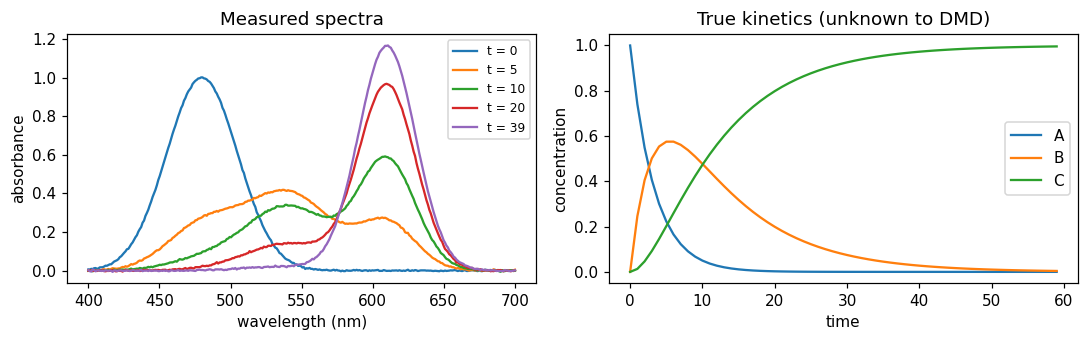

In [9]:
k1, k2 = 0.30, 0.10                  # true rate constants (1/time)
tau = 1.0                            # time between spectra
n_all = 60                           # we generate 60 spectra: the first 40 are "measured", the last 20 are the future
t = np.arange(n_all) * tau
cA = np.exp(-k1 * t)
cB = k1 / (k2 - k1) * (np.exp(-k1 * t) - np.exp(-k2 * t))
cC = 1.0 - cA - cB
conc = np.vstack([cA, cB, cC])                                   # 3 x n_all

wl = np.linspace(400, 700, 300)                                  # wavelengths (nm)
band = lambda c0, w: np.exp(-0.5 * ((wl - c0) / w) ** 2)
eps_spec = np.vstack([1.0 * band(480, 25), 0.7 * band(540, 30), 1.2 * band(610, 20)]).T   # 300 x 3 spectra
V_clean = eps_spec @ conc                                        # 300 x n_all
noise = 0.002
V_all = V_clean + noise * rng.normal(size=V_clean.shape)

n_obs = 40
V_obs = V_all[:, :n_obs]                                         # what we "measure"

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for j in (0, 5, 10, 20, 39):
    ax[0].plot(wl, V_obs[:, j], label=f"t = {t[j]:.0f}")
ax[0].set(xlabel="wavelength (nm)", ylabel="absorbance", title="Measured spectra"); ax[0].legend(fontsize=8)
ax[1].plot(t, conc.T); ax[1].legend(["A", "B", "C"]); ax[1].set(xlabel="time", ylabel="concentration", title="True kinetics (unknown to DMD)")
plt.tight_layout(); plt.show()

**Choosing $r$.** Plot the singular values of $X$ on a logarithmic scale and look for a gap: the large ones are signal, the plateau of small ones is noise.

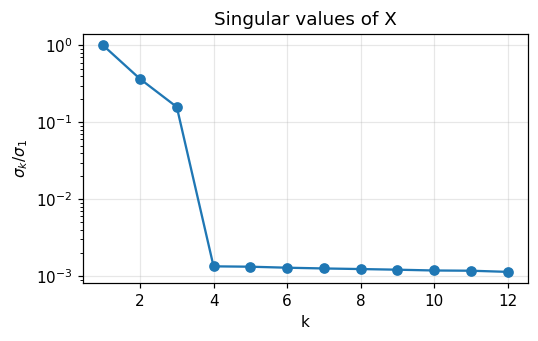

sigma_k / sigma_1 for k = 1..6: [1.     0.3675 0.1586 0.0013 0.0013 0.0013]


In [10]:
X_obs = V_obs[:, :-1]
s_obs = np.linalg.svd(X_obs, compute_uv=False)

plt.figure(figsize=(5, 3.2))
plt.semilogy(np.arange(1, 13), s_obs[:12] / s_obs[0], "o-")
plt.xlabel("k"); plt.ylabel(r"$\sigma_k/\sigma_1$"); plt.title("Singular values of X"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("sigma_k / sigma_1 for k = 1..6:", s_obs[:6] / s_obs[0])

true  lambda: [1.     0.9048 0.7408]
DMD   lambda: [1.     0.9051 0.7404] (imaginary parts ~ 0.0 )
DMD   rate constants -Re(mu): [0.3005 0.0997 0.    ]    true: [0.3, 0.1, 0.0]
relative error vs the noise-free spectra:  observed window mean 0.0018,  prediction mean 0.0013


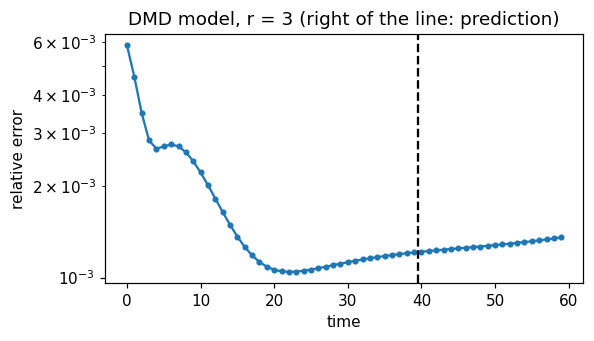

In [11]:
r = 3                                                    # <- Your turn: try r = 2, 3, 5, 10 and watch what happens below
lam, Gam, c, s = dmd(V_obs, r=r)

print("true  lambda:", np.sort([np.exp(-k1 * tau), np.exp(-k2 * tau), 1.0])[::-1])
print("DMD   lambda:", np.sort(lam.real)[::-1], "(imaginary parts ~", np.abs(lam.imag).max().round(4), ")")
mu = np.log(lam.astype(complex)) / tau
print("DMD   rate constants -Re(mu):", np.sort(-mu.real)[::-1], "   true:", [0.0, k2, k1][::-1])

V_model = propagate(lam, Gam, c, n_all)                  # 60 snapshots: 40 observed + 20 predicted
err = np.linalg.norm(V_model - V_clean, axis=0) / np.linalg.norm(V_clean, axis=0)
print(f"relative error vs the noise-free spectra:  observed window mean {err[:n_obs].mean():.4f},  prediction mean {err[n_obs:].mean():.4f}")

plt.figure(figsize=(5.5, 3.2))
plt.semilogy(t, err, "o-", ms=3); plt.axvline(t[n_obs] - 0.5, color="k", ls="--")
plt.xlabel("time"); plt.ylabel("relative error"); plt.title(f"DMD model, r = {r} (right of the line: prediction)")
plt.tight_layout(); plt.show()

With $r=3$ DMD recovers the two rate constants and the eigenvalue $1$ (the final state), and the prediction of the next 20 spectra has an error of about $0.1\%$, comparable to the noise in the data. The modes are mixtures of the three species spectra (an eigenvector is a combination of the $\varepsilon_s$), not the species spectra themselves.

**Your turn.**
* Set `r = 2` above: you lose a real process and the error jumps to about $10$–$20\%$. With `r = 1` it is about $80\%$.
* Set `r = 5`, `10` or even `20`: in this example the result hardly changes, because the noise is small and the extra modes have tiny amplitudes (the error even creeps up slightly). Keeping too many modes is not always catastrophic for linear, low-noise data, but Part D shows a case where it is.
* Raise `noise` (in the data cell above) to $0.02$ and re-run from there. How well are the rate constants recovered now? (In our test they stayed within a few percent.)

This is the situation in which DMD shines: the dynamics is **linear** in the measured quantities, the number of modes is small, and the noise is moderate.
This is the situation in which DMD shines: the dynamics is **linear** in the measured quantities, the number of modes is small, and the noise is moderate.

---
# Part D. Exercise: a moving two-dimensional Gaussian

A two-dimensional Gaussian whose centre oscillates,
$$\psi(x,y,t)=e^{-(x-x_e(t))^2-(y-y_e(t))^2},\qquad x_e=A_x\cos(\omega_xt),\quad y_e=A_y\cos(\omega_yt),$$
with $A_x=0.5$, $A_y=0.1$, $\omega_x=\pi/T$, $\omega_y=0.5+\pi/T$ and total observation time $T=30$. We sample $\psi$ on a $50\times50$ grid ($-2\le x,y<2$) at $n=30$ times $t_j=j-1$ ($\tau=1$). Each snapshot has $N=2500$ numbers.

**Tasks.** (a) generate and look at the data; (b) SVD of $X$ and choice of $\epsilon$; (c) eigenvalues and modes; (d) compare phases with $\omega_x,\omega_y$; (e) amplitudes, reconstruction and error; (f) **predict** the next 30 snapshots. Is the prediction reliable?

### (a) The data

snapshot matrix shape: (2500, 30)


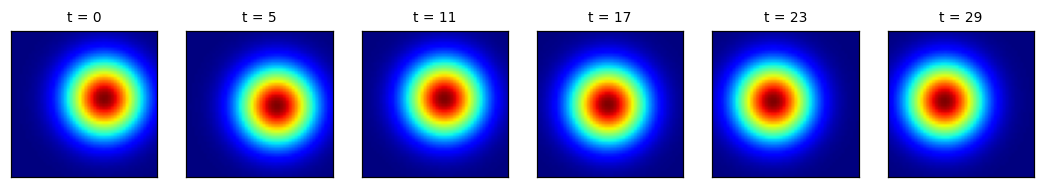

In [12]:
npt, L = 50, 4.0                              # grid points per dimension, box length
nt = 30                                       # observed snapshots (time step 1, so T = 30)
n_extra = 30                                  # extra "future" snapshots, only used to TEST the prediction
Ax, Ay = 0.5, 0.1                             # amplitudes of the oscillation of the Gaussian's centre
wx, wy = np.pi / 30, 0.5 + np.pi / 30         # angular frequencies (fixed: they do not depend on how long we observe)
dz = L / npt
z = (np.arange(npt) - npt / 2) * dz           # grid coordinates

def make_data(n_steps):
    """psi[i, j, k] = psi(x_i, y_j, t_k), t_k = k, for k = 0..n_steps-1"""
    k = np.arange(n_steps)
    gx = np.exp(-(z[:, None] - (Ax * np.cos(wx * k))[None, :]) ** 2)      # (npt, n_steps): x-factor
    gy = np.exp(-(z[:, None] - (Ay * np.cos(wy * k))[None, :]) ** 2)      # (npt, n_steps): y-factor
    return np.einsum("ik,jk->ijk", gx, gy)

def show(ax, field, title=None, vmin=None, vmax=None, cmap="jet"):
    """Draw a field[i, j] (i = x index, j = y index) with x horizontal, y vertical."""
    ax.imshow(field.T, origin="lower", extent=[-L / 2, L / 2, -L / 2, L / 2], cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=9)

data_all = make_data(nt + n_extra)
data = data_all[:, :, :nt]
N = npt * npt
Vg = data.reshape(N, nt)                      # snapshot matrix: 2500 x 30
Vg_all = data_all.reshape(N, nt + n_extra)
print("snapshot matrix shape:", Vg.shape)

fig, axs = plt.subplots(1, 6, figsize=(12, 2.3))
for a, k in zip(axs, np.linspace(0, nt - 1, 6).astype(int)):
    show(a, data[:, :, k], f"t = {k}", vmin=0, vmax=1)
plt.show()

The motion is small compared with the width of the Gaussian (the amplitudes are $0.5$ and $0.1$, the width is about $0.7$), so the movie looks almost static. Run the optional movie cell if you like.

In [13]:
SHOW_MOVIES = True            # <- set False to skip the movies

def make_movie(frames, title="", vmax=1.0):
    fig, ax = plt.subplots(figsize=(3, 3))
    im = ax.imshow(frames[0].T, origin="lower", extent=[-L/2, L/2, -L/2, L/2], cmap="jet", vmin=0, vmax=vmax)
    ax.set_xticks([]); ax.set_yticks([])
    def update(k):
        im.set_data(frames[k].T); ax.set_title(f"{title} t = {k}", fontsize=9); return (im,)
    anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=150)
    plt.close(fig)
    return anim

if SHOW_MOVIES:
    from IPython.display import HTML
    display(HTML(make_movie([data[:, :, k] for k in range(nt)], "data").to_jshtml()))

### (b) SVD of $X$ and the choice of $\epsilon$

We build $X$ and $Y$ and look at the singular values. Gaussians displaced by small amounts are almost linearly dependent, so we expect them to decay quickly. The DMD formulas divide by the singular values, so **tiny singular values must not be kept** (they would amplify rounding errors).

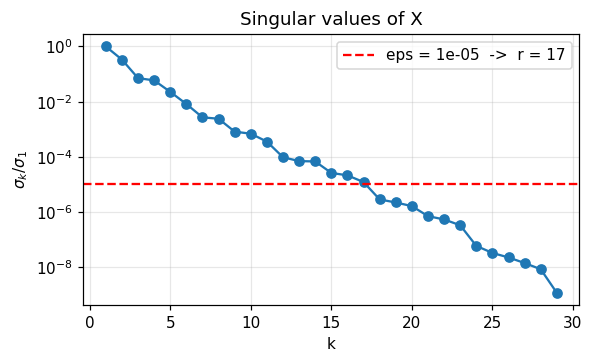

keeping r = 17 of 29 singular values


In [14]:
Xg, Yg = Vg[:, :-1], Vg[:, 1:]
sg = np.linalg.svd(Xg, compute_uv=False)

eps = 1e-5                                    # <- Your turn: singular values below eps * sigma_1 are discarded
r_g = int(np.sum(sg > eps * sg[0]))

plt.figure(figsize=(5.5, 3.4))
plt.semilogy(np.arange(1, len(sg) + 1), sg / sg[0], "o-")
plt.axhline(eps, color="r", ls="--", label=f"eps = {eps:g}  ->  r = {r_g}")
plt.xlabel("k"); plt.ylabel(r"$\sigma_k/\sigma_1$"); plt.title("Singular values of X"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"keeping r = {r_g} of {len(sg)} singular values")

### (c) Eigenvalues and modes

r = 17   max|lambda| = 1.0293   min|lambda| = 0.0397


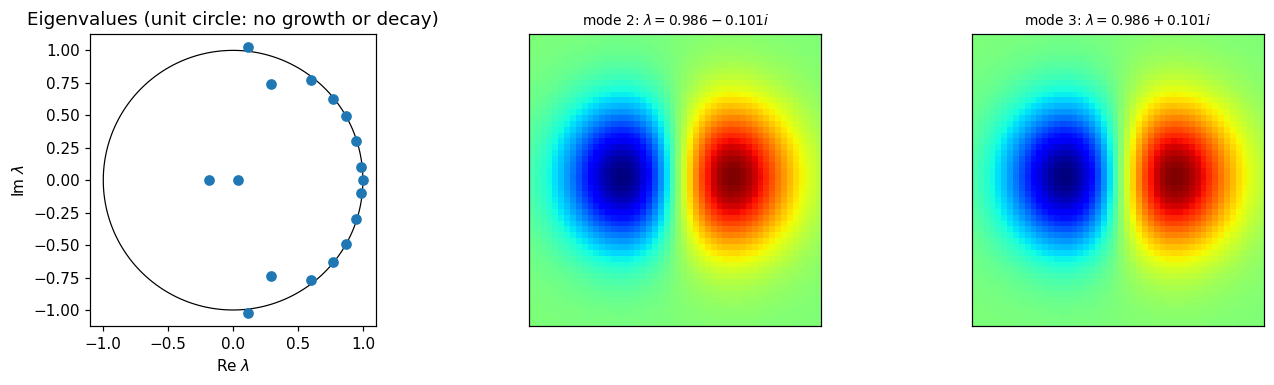

In [15]:
lam_g, Gam_g, c_g, s_g = dmd(Vg, eps=eps)

# sort the modes by importance |c_k| * ||Gamma_k||
order = np.argsort(-np.abs(c_g) * np.linalg.norm(Gam_g, axis=0))
lam_g, Gam_g, c_g = lam_g[order], Gam_g[:, order], c_g[order]
print(f"r = {len(lam_g)}   max|lambda| = {np.abs(lam_g).max():.4f}   min|lambda| = {np.abs(lam_g).min():.4f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
th = np.linspace(0, 2 * np.pi, 200)
axs[0].plot(np.cos(th), np.sin(th), "k-", lw=0.8)
axs[0].plot(lam_g.real, lam_g.imag, "o")
axs[0].set(xlabel="Re $\\lambda$", ylabel="Im $\\lambda$", title="Eigenvalues (unit circle: no growth or decay)", aspect="equal")
for j, a in enumerate(axs[1:]):
    show(a, Gam_g[:, j + 1].real.reshape(npt, npt), rf"mode {j + 2}: $\lambda={lam_g[j + 1].real:.3f}{lam_g[j + 1].imag:+.3f}i$")
plt.tight_layout(); plt.show()

### (d) Do the eigenvalue phases match the known frequencies?
The phase of $\lambda$ is $\omega\tau$ for a mode oscillating at angular frequency $\omega$. We know $\omega_x\tau=\pi/30\approx0.105$ and $\omega_y\tau\approx0.605$.

In [16]:
print(f"known:  omega_x*tau = {wx:.4f},   omega_y*tau = {wy:.4f}\n")
print(" rank    |lambda|    arg(lambda)    relative amplitude")
imp = np.abs(c_g) * np.linalg.norm(Gam_g, axis=0)
for k in range(8):
    print(f" {k + 1:4d}    {abs(lam_g[k]):.4f}    {np.angle(lam_g[k]):+.4f}        {imp[k] / imp[0]:.3f}")

known:  omega_x*tau = 0.1047,   omega_y*tau = 0.6047

 rank    |lambda|    arg(lambda)    relative amplitude
    1    1.0000    +0.0000        1.000
    2    0.9912    -0.1023        0.302
    3    0.9912    +0.1023        0.302
    4    0.9932    -0.3071        0.044
    5    0.9932    +0.3071        0.044
    6    1.0030    -0.5142        0.044
    7    1.0030    +0.5142        0.044
    8    0.9941    -0.6841        0.034


The strongest mode has $\lambda=1$: the average shape, which does not change. The strongest oscillating pair has a phase close to $\omega_x\tau$: **the slow oscillation was found from the data alone**. The remaining modes describe the change of shape of the Gaussian and the fast, small $y$-motion; with only 30 snapshots (half a period of the $x$ oscillation) their individual frequencies should not be over-interpreted.

### (e) Amplitudes, reconstruction, error

observed window  (t = 0..29): mean relative error 0.033,  max 0.048
prediction (t = 30..59): mean relative error 0.310,  max 0.482

integral of psi at t = 0, 10, 20 (exact vs DMD): ['3.063 vs 3.063', '3.098 vs 3.100', '3.104 vs 3.101']


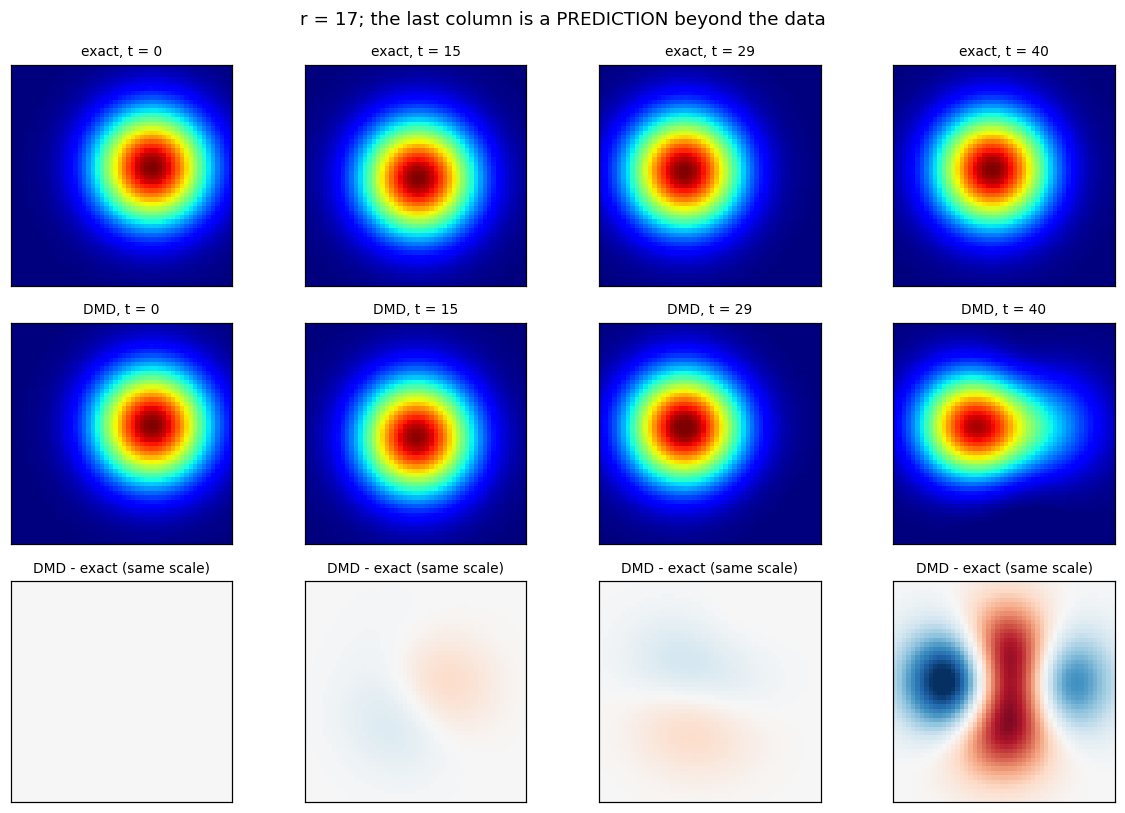

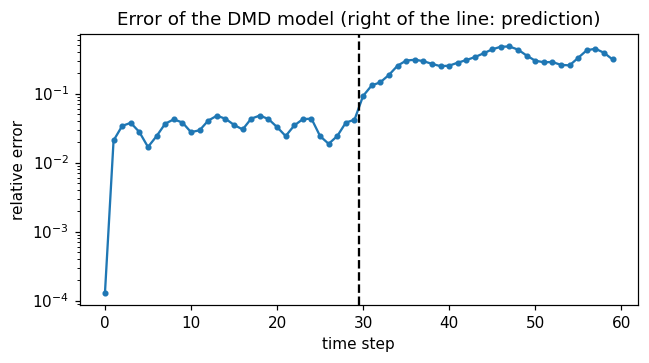

In [17]:
n_total = nt + n_extra
recon = propagate(lam_g, Gam_g, c_g, n_total)                  # model for t = 0..59 (30 observed + 30 predicted)
err_g = np.linalg.norm(recon - Vg_all, axis=0) / np.linalg.norm(Vg_all, axis=0)

print(f"observed window  (t = 0..{nt - 1}): mean relative error {err_g[:nt].mean():.3f},  max {err_g[:nt].max():.3f}")
print(f"prediction (t = {nt}..{n_total - 1}): mean relative error {err_g[nt:].mean():.3f},  max {err_g[nt:].max():.3f}")

# sanity check: the integral of psi over the plane is ~pi (reduced a little by the finite box)
I_exact, I_model = Vg_all.sum(axis=0) * dz ** 2, recon.sum(axis=0) * dz ** 2
print("\nintegral of psi at t = 0, 10, 20 (exact vs DMD):", [f"{I_exact[k]:.3f} vs {I_model[k]:.3f}" for k in (0, 10, 20)])

fig, axs = plt.subplots(3, 4, figsize=(11, 7.5))
for col, k in enumerate((0, nt // 2, nt - 1, nt + 10)):
    show(axs[0, col], Vg_all[:, k].reshape(npt, npt), f"exact, t = {k}", vmin=0, vmax=1)
    show(axs[1, col], recon[:, k].reshape(npt, npt), f"DMD, t = {k}", vmin=0, vmax=1)
    show(axs[2, col], (recon[:, k] - Vg_all[:, k]).reshape(npt, npt), "DMD - exact (same scale)", vmin=-0.2, vmax=0.2, cmap="RdBu")
fig.suptitle(f"r = {len(lam_g)}; the last column is a PREDICTION beyond the data")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.4))
plt.semilogy(err_g, "o-", ms=3); plt.axvline(nt - 0.5, color="k", ls="--")
plt.xlabel("time step"); plt.ylabel("relative error"); plt.title("Error of the DMD model (right of the line: prediction)")
plt.tight_layout(); plt.show()

Within the observed window the model is good (a few percent, and the conserved integral is reproduced). The error is not exactly zero even at $t=0$: the amplitudes come from projecting $v_1$ onto the modes, and $v_1$ is not exactly in their span.

**Beyond the observed window the model deteriorates.** (In our test run: about 3% mean error inside the window, about 30% for the following 30 steps.) How does this depend on $\epsilon$?

### (f) How many modes? The effect of $\epsilon$

In [18]:
print("   eps      r   error in observed window   error in next 30 steps   max|lambda|")
rows = []
for e in (1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-8):
    l, G, c, _ = dmd(Vg, eps=e)
    R = propagate(l, G, c, n_total)
    ee = np.linalg.norm(R - Vg_all, axis=0) / np.linalg.norm(Vg_all, axis=0)
    rows.append((e, len(l), ee[:nt].mean(), ee[nt:].mean()))
    print(f"{e:8.0e}  {len(l):3d}          {ee[:nt].mean():8.3f}                {ee[nt:].mean():8.3f}         {abs(l).max():.3f}")

   eps      r   error in observed window   error in next 30 steps   max|lambda|
   1e-02    5             0.070                   0.305         1.005
   1e-03    8             0.060                   0.353         0.999
   1e-04   11             0.064                   0.786         1.017
   1e-05   17             0.033                   0.310         1.029
   1e-06   20             0.022                   1.160         1.106
   1e-08   27             0.029                   3.357         1.080


More modes describe the observed window slightly better, but the prediction gets **worse**, and modes with $|\lambda|>1$ appear. The extra modes are fitting the 29 observed snapshots (interpolation) rather than the dynamics.

### Does a longer observation help?
Let's observe for 30, 60, 90 and 120 snapshots (the frequencies stay the same) and predict the next 30.

In [19]:
data_long = make_data(120 + 30).reshape(N, 150)
print(" n_observed   r    error in window   error in next 30 steps")
for ntr in (30, 60, 90, 120):
    l, G, c, _ = dmd(data_long[:, :ntr], eps=1e-5)
    R = propagate(l, G, c, ntr + 30)
    ee = np.linalg.norm(R - data_long[:, :ntr + 30], axis=0) / np.linalg.norm(data_long[:, :ntr + 30], axis=0)
    print(f"   {ntr:4d}      {len(l):3d}      {ee[:ntr].mean():8.3f}           {ee[ntr:].mean():8.3f}")

 n_observed   r    error in window   error in next 30 steps
     30       17         0.033              0.310
     60       17         0.395              0.308
     90       17         0.357              0.415
    120       17         0.368              0.308


**A longer record does not fix the prediction**: in this test the errors stay around 30–40%, and the error inside the observed window actually grows.

### Why does DMD fail here, while it worked in Part C?
DMD assumes the snapshots are generated by **one time-independent linear matrix**: $v_{j+1}=Av_j$.

* In Part C the spectra are *linear combinations* of three fixed spectra with kinetics-determined weights: a genuinely linear, 3-dimensional problem. DMD found it exactly.
* Here the shape of $\psi$ depends **nonlinearly** on the centre position $x_e(t),y_e(t)$. The movie is low-rank (17 modes describe 29 snapshots) but **low-rank data is not the same as low-dimensional linear dynamics**: representing the translating Gaussian with exponentials needs many modes, and the short record cannot determine them. A model with that many free parameters merely interpolates.

DMD still gave useful *analysis* (the slow frequency was found, the movie was compressed to 17 modes), but not a reliable *prediction*. Knowing the limits of a method is part of knowing the method. Ways forward are richer observables (extended DMD), nonlinear methods, or physical knowledge of the system.

### Check yourself
1. $N=5000$ wavelengths, $n=101$ spectra, $r=4$. What are the shapes of $X$, $U$, $\Sigma$, $V$, $\tilde A$ and $\Gamma$, and how many entries would the full matrix $A$ have?
2. DMD returns $\lambda=0.9\,e^{\pm0.4i}$ for $\tau=2$ ps. What are the decay rate, lifetime and oscillation period?
3. The singular values are $10,\,5,\,0.3,\,0.001,\,0.0008$. How many would you keep, and what else do you need to know?

<details><summary>Answers</summary>

1. $X$: $5000\times100$; $U$: $5000\times4$; $\Sigma$: $4\times4$; $V$: $100\times4$; $\tilde A$: $4\times4$; $\Gamma$: $5000\times4$; $A$ would have $5000^2=2.5\times10^7$ entries.
2. $\mu=\ln\lambda/\tau$: decay rate $-\ln(0.9)/2\approx0.053\ \mathrm{ps}^{-1}$ (lifetime $\approx19$ ps), angular frequency $0.4/2=0.2$ rad/ps (period $2\pi/0.2\approx31$ ps).
3. There is a gap after the third value. If the noise floor is around $10^{-3}$, keep $r=3$; if the noise were as large as $0.3$, only two values would be significant. It depends on the noise level.
</details>

In [20]:
# Quick numerical check of answer 2
lam_q, tau_q = 0.9 * np.exp(0.4j), 2.0
mu_q = np.log(lam_q) / tau_q
print("decay rate:", -mu_q.real, "1/ps | lifetime:", -1 / mu_q.real, "ps | period:", 2 * np.pi / mu_q.imag, "ps")

decay rate: 0.05268025782891312 1/ps | lifetime: 18.982443162059816 ps | period: 31.41592653589793 ps


---
# Part E. Summary

### The DMD recipe
Given snapshots $v_1,\dots,v_n$ at times $(j-1)\tau$:

1. $X=[v_1\cdots v_{n-1}]$, $Y=[v_2\cdots v_n]$.
2. Truncated SVD $X\approx U\Sigma V^T$, keeping $r$ singular values $\sigma_k>\epsilon\sigma_1$.
3. $\tilde A=U^TYV\Sigma^{-1}$ and its eigenproblem $\tilde A\tilde\Gamma_k=\lambda_k\tilde\Gamma_k$.
4. Modes $\Gamma_k=\lambda_k^{-1}YV\Sigma^{-1}\tilde\Gamma_k$.
5. Amplitudes $c=(\Gamma^\dagger\Gamma)^{-1}\Gamma^\dagger v_1$.
6. Prediction $v_j=\sum_kc_k\lambda_k^{\,j-1}\Gamma_k$, i.e. $v(t)=\sum_kc_ke^{\mu_kt}\Gamma_k$ with $\mu_k=\ln\lambda_k/\tau$.

### Practical advice
* **Choose $r$** (or $\epsilon$) from a log plot of the singular values; keeping too many modes fits noise and can produce growing modes.
* **DMD is a linear model.** It is exact for linear dynamics (e.g. first-order kinetics) and only a linear approximation otherwise. Do not trust long extrapolations.
* **Sampling:** the time step must be short enough that no mode turns by more than half a period per step, otherwise the frequency $\arg\lambda/\tau$ is ambiguous (aliasing).
* **Always test the prediction** on data that was held out, as we did in Parts C and D.

### More exercises
1. In Part C, make $k_2$ closer and closer to $k_1$ (and raise the noise). At what point do the recovered rate constants become inaccurate, and why should two similar rates be hard to tell apart?
2. In Part C, add a fourth species (e.g. C → D) and see how many singular values are above the noise.
3. In Part D, estimate the amplitudes by least-squares fitting **all** snapshots instead of only the first one. (In our test this reduced the in-window error to about 0.2% at $\epsilon=10^{-5}$, but did not improve the prediction.)
4. In Part D, use the parameters $A_x=0.7$, $A_y=0.3$, $\omega_x=\pi/50$, $\omega_y=0.5+\pi/50$ of an earlier version of this exercise. How do the results change?
5. Add noise to the Gaussian data. How does the best $\epsilon$ change?
6. (Advanced) For large grids, DMD can be done with tensor trains; see the `scikit_tt` package (https://github.com/PGelss/scikit_tt).

### Troubleshooting
| Symptom | Likely cause |
|---|---|
| Huge errors or enormous eigenvalues | $\epsilon$ too small (noise modes kept); raise $\epsilon$ or lower $r$ |
| `LinAlgError` or `nan` in `dmd` | an eigenvalue is exactly 0 (division by $\lambda$), or the overlap matrix is singular: lower $r$ |
| Movie cell prints nothing | set `SHOW_MOVIES = False`, or re-run the cell; movies need a browser that allows inline JavaScript |
| Results differ slightly from the text | random noise or different library versions; the Gaussian example has no randomness |

### References
* P. J. Schmid, *Dynamic mode decomposition of numerical and experimental data*, J. Fluid Mech. **656**, 5–28 (2010).
* J. H. Tu, C. W. Rowley, D. M. Luchtenburg, S. L. Brunton, J. N. Kutz, *On dynamic mode decomposition: theory and applications*, J. Comput. Dyn. **1**, 391–421 (2014).
* J. N. Kutz, S. L. Brunton, B. W. Brunton, J. L. Proctor, *Dynamic Mode Decomposition: Data-Driven Modeling of Complex Systems*, SIAM (2016).
* S. Klus, P. Gelß, S. Peitz, C. Schütte, *Tensor-based dynamic mode decomposition*, Nonlinearity **31**, 3359 (2018).